# 01: profiling the four sources

Wildfire monitoring, Team 3, Data Analysis Programming 2026-II, Workshop 1
deliverable 2. Hazard: vegetation fires seen as satellite thermal anomalies, with
FRP in MW as the severity measure. Scope: Colombia, 33 regions.

Four sources, profiled on the raw responses kept in `workshop_1/samples/`:

| # | Role | Source |
|---|---|---|
| F1 | Historical | NASA FIRMS archive (standard processing, `*_SP`) |
| F2 | Historical | Open-Meteo Historical Weather (ERA5 reanalysis) |
| F3 | Incremental | NASA FIRMS NRT (VIIRS NOAA-20 and NOAA-21) |
| F4 | Incremental | Open-Meteo Forecast |

The notebook goes through what each source contains, what is wrong with it,
whether two sources describe the same fire, and what all of that forces in the
canonical model.

Run it from the repository root:

```powershell
$env:PYTHONPATH = "$PWD/vendor;$PWD/src"
jupyter nbconvert --to notebook --execute notebooks/01_source_profiling.ipynb --inplace
```

In [1]:
import sys
from pathlib import Path

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

SAMPLES = ROOT / "workshop_1" / "samples"
RAW = ROOT / "data" / "raw"
FIGURES = ROOT / "docs" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

BBOX_WEST, BBOX_SOUTH, BBOX_EAST, BBOX_NORTH = -79.0, -4.5, -66.5, 13.5
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 30)
print("project root :", ROOT)
print("samples      :", len(list(SAMPLES.glob('*'))), "files")

project root : C:\Users\cesar\OneDrive\Documentos\2026-3\Data_Analysis_Programming
samples      : 13 files


## 0. A reusable profiler

Every source gets the same six checks: null share per field, value ranges,
duplicated identifiers, timestamp format and time zone, coordinate validity and
unit consistency. Six is enough to catch everything we found, and it keeps the
output comparable between sources.

In [2]:
def profile_table(frame: pd.DataFrame, name: str) -> pd.DataFrame:
    """Per-field profile: dtype, null %, cardinality, range for numeric fields."""
    rows = []
    for column in frame.columns:
        series = frame[column]
        row = {
            "field": column,
            "dtype": str(series.dtype),
            "null_pct": round(float(series.isna().mean()) * 100, 2),
            "n_unique": int(series.nunique(dropna=True)),
        }
        if pd.api.types.is_numeric_dtype(series) and series.notna().any():
            row["min"] = float(series.min())
            row["max"] = float(series.max())
        rows.append(row)
    table = pd.DataFrame(rows)
    print(f"=== {name}: {len(frame):,} rows x {frame.shape[1]} columns ===")
    return table


def bbox_violations(frame: pd.DataFrame, lat="latitude", lon="longitude") -> int:
    outside = ~frame[lat].between(BBOX_SOUTH, BBOX_NORTH) | ~frame[lon].between(BBOX_WEST, BBOX_EAST)
    return int(outside.sum())


print("helpers defined")

helpers defined


## 1. F3: NASA FIRMS NRT (VIIRS NOAA-20 and NOAA-21)

The area API takes at most five days per request:

In [3]:
files = sorted(SAMPLES.glob("firms_VIIRS_NOAA2*_colombia_5d_*.csv"))
parts = []
for path in files:
    block = pd.read_csv(path)
    block["raw_reference"] = path.name
    parts.append(block)
f3 = pd.concat(parts, ignore_index=True)

profile_table(f3, "F3 FIRMS NRT")
print()
print(f3.head(3).to_string(index=False))

=== F3 FIRMS NRT: 2,220 rows x 15 columns ===

 latitude  longitude  bright_ti4  scan  track   acq_date  acq_time satellite instrument confidence version  bright_ti5  frp daynight                                           raw_reference
  9.73813  -73.50816      306.26  0.55   0.51 2026-11-10       658       N20      VIIRS          n  2.0NRT      293.71 3.08        N firms_VIIRS_NOAA20_NRT_colombia_5d_20261114T025629Z.csv
  9.74365  -73.51219      306.48  0.55   0.51 2026-11-10       658       N20      VIIRS          n  2.0NRT      293.09 1.94        N firms_VIIRS_NOAA20_NRT_colombia_5d_20261114T025629Z.csv
  9.76056  -73.47366      306.47  0.55   0.51 2026-11-10       658       N20      VIIRS          n  2.0NRT      293.19 1.85        N firms_VIIRS_NOAA20_NRT_colombia_5d_20261114T025629Z.csv


### Finding 1: the duplicate count depends on the tolerance you pick

Exact duplicates are zero. On a ~1 km grid and the same day, 44.5 % of rows share
a cell. The result is not a property of the data, it is a property of the test,
and that is the evidence behind the workshop warning about grouping detections
into fire events.

In [4]:
exact = f3.duplicated(subset=["latitude", "longitude", "acq_date", "acq_time", "satellite"]).sum()
print(f"exact duplicates                              : {exact}")

duplicate_scan = []
for decimals in (3, 2, 1):
    grid = f3.assign(lat_g=f3.latitude.round(decimals), lon_g=f3.longitude.round(decimals))
    involved = int(grid.duplicated(subset=["lat_g", "lon_g", "acq_date"], keep=False).sum())
    duplicate_scan.append({
        "tolerance_deg": decimals,
        "approx_km": round(111 * 10 ** -decimals, 2),
        "rows_involved": involved,
        "pct": round(involved / len(f3) * 100, 1),
    })
duplicates = pd.DataFrame(duplicate_scan)
print(duplicates.to_string(index=False))

exact duplicates                              : 0
 tolerance_deg  approx_km  rows_involved  pct
             3       0.11             31  1.4
             2       1.11            987 44.5
             1      11.10           1495 67.3


### Finding 2: `acq_time` is HHMM without zero padding

436 rows carry a three-digit `acq_time`, so `630` means 06:30. Read as an integer
the value silently becomes 630 minutes or 6.30 hours, depending on the code.
Those 436 rows are exactly the night detections.

In [5]:
f3["acq_time_str"] = f3.acq_time.astype(int).astype(str)
f3["acq_time_digits"] = f3.acq_time_str.str.len()

print("how many digits does acq_time have:")
print(f3.acq_time_digits.value_counts().sort_index().to_string())
print()
print("cross-tab with daynight (the 3-digit rows are the night ones):")
print(pd.crosstab(f3.acq_time_digits, f3.daynight).to_string())
print()
print("examples of 3-digit acq_time values:", f3.loc[f3.acq_time_digits == 3, "acq_time"].head(6).tolist())

how many digits does acq_time have:
acq_time_digits
3     436
4    1784

cross-tab with daynight (the 3-digit rows are the night ones):
daynight            D    N
acq_time_digits           
3                   0  436
4                1784    0

examples of 3-digit acq_time values: [658, 658, 658, 658, 658, 658]


### Finding 3: FRP values that cannot be right

One row has an FRP of zero, which cannot be a fire detection, and 86 sit below
1 MW, at the noise floor of the product. Both distort any total.

In [6]:
print("FRP == 0      :", int((f3.frp == 0).sum()))
print("FRP < 1 MW    :", int((f3.frp < 1).sum()))
print("FRP statistics:", {k: round(float(v), 2) for k, v in f3.frp.describe().items()})
print()
print("a record with FRP = 0:")
print(f3.loc[f3.frp == 0].head(2).to_string(index=False))

FRP == 0      : 1
FRP < 1 MW    : 86
FRP statistics: {'count': 2220.0, 'mean': 6.96, 'std': 9.92, 'min': 0.0, '25%': 3.05, '50%': 4.78, '75%': 7.92, 'max': 196.02}

a record with FRP = 0:
 latitude  longitude  bright_ti4  scan  track   acq_date  acq_time satellite instrument confidence version  bright_ti5  frp daynight                                           raw_reference acq_time_str  acq_time_digits
 10.49044  -71.63353      305.47  0.39   0.36 2026-11-12       622       N20      VIIRS          n  2.0NRT      291.68  0.0        N firms_VIIRS_NOAA20_NRT_colombia_5d_20261114T025629Z.csv          622                3


### Finding 4: `confidence` is a code, not a percentage

VIIRS returns `l`, `n` or `h`. MODIS returns 0–100. A filter like
`confidence > 50` means nothing on VIIRS, and unioning both sensors without
normalising silently keeps or drops everything.

In [7]:
print("confidence values (VIIRS):", f3.confidence.value_counts().to_dict())
print("is the column numeric? :", pd.api.types.is_numeric_dtype(f3.confidence))
print()
print("Applying 'confidence > 50' to VIIRS would keep:",
      int((pd.to_numeric(f3.confidence, errors="coerce") > 50).sum()), "rows out of", len(f3))

confidence values (VIIRS): {'n': 2087, 'l': 79, 'h': 54}
is the column numeric? : False

Applying 'confidence > 50' to VIIRS would keep: 0 rows out of 2220


### Finding 5: the bounding box is not the country

The API only takes a bounding box, and the Colombian box contains Venezuela,
Ecuador, Peru, Brazil and Panama. Assigning each detection to a department with a
point-in-polygon test shows that half the rows are fires somewhere else.

In [8]:
from normalization.regions import assign_regions, load_regions

regions = load_regions()
print("regions loaded:", len(regions))

f3 = assign_regions(f3)
inside = int(f3.region_id.notna().sum())
print(f"detections total     : {len(f3)}")
print(f"inside Colombia      : {inside} ({inside / len(f3):.1%})")
print(f"OUTSIDE (neighbouring countries) : {len(f3) - inside} ({(len(f3) - inside) / len(f3):.1%})")

regions loaded: 33
detections total     : 2220
inside Colombia      : 1109 (50.0%)
OUTSIDE (neighbouring countries) : 1111 (50.0%)


In [9]:
top_regions = (
    f3.dropna(subset=["region_name"])
    .groupby("region_name")
    .agg(detections=("frp", "size"), frp_sum=("frp", "sum"), frp_max=("frp", "max"))
    .sort_values("detections", ascending=False)
    .round(1)
)
print("Top 10 departments by detections (5 days):")
print(top_regions.head(10).to_string())
print()
print("regions with no detections:", 33 - top_regions.shape[0])

Top 10 departments by detections (5 days):
                    detections  frp_sum  frp_max
region_name                                     
Norte de Santander         175   1923.9    196.0
Antioquia                  143   1341.0     79.7
Vichada                    133    972.4     30.1
Bolívar                     96    596.1     15.1
Meta                        82    480.1     20.6
Santander                   75    750.8     61.9
Cesar                       63    283.1     19.7
Tolima                      48    278.4     31.8
La Guajira                  42    161.3     10.3
Magdalena                   40    187.1     12.8

regions with no detections: 4


## 2. F1: the FIRMS archive (standard processing)

The `*_SP` sources serve archive-quality records and the API accepts historical
dates for them, five days at a time (the partitioned pull lives in
`tools/pull_history.py`). The `*_NRT` sources only answer for the recent window: a
request for 2024-01-22 comes back empty.

In [10]:
history_dir = RAW / "firms_history" / "2024"
frames = []
for source_dir in sorted(history_dir.glob("*")):
    if not source_dir.is_dir():
        continue
    parts = [pd.read_csv(f) for f in sorted(source_dir.glob("*.csv"))]
    if not parts:
        continue
    block = pd.concat(parts, ignore_index=True)
    block["sensor"] = source_dir.name
    frames.append(block)

if frames:
    f1 = pd.concat(frames, ignore_index=True)
    f1["region_id"] = np.nan
    profile_table(f1, "F1 FIRMS archive 2024")
else:
    f1 = pd.DataFrame()
    print("No archive data yet: run tools/pull_history.py 2024 VIIRS_NOAA20_SP")

=== F1 FIRMS archive 2024: 703,633 rows x 19 columns ===


### Comparing sensors (the 2026 discontinuities)

Suomi NPP stopped on 2026-11-02 and Terra MODIS has been in standby since March
2026. A baseline that mixes sensors measures the instruments. That is why the
baseline here is built per sensor, and the cell below shows what happens if you
forget it.

One detail about the numbers that follow: the pull runs in 5-day windows from
2024-01-01, so the 73rd window ends on 2025-01-03. The totals include those three
extra days, which is why the last point of the chart is small.

Detections per month and sensor (Colombia bbox):
sensor    MODIS_SP  VIIRS_NOAA20_SP  VIIRS_SNPP_SP
acq_date                                          
2024-01      16538            70345          71360
2024-02      13357            54920          58157
2024-03      17613            75636          81686
2024-04       8144            41388          42537
2024-05        793             4122           3672
2024-06        558             2519           1997
2024-07        849             4526           2634
2024-08       2538            10704          10805
2024-09       2694            11344          11358
2024-10       2386            10723          10196
2024-11       2046             7832           8002
2024-12       3905            16467          16518
2025-01        399             1306           1059

Totals per sensor and the ratio between them:
sensor
MODIS_SP            71820
VIIRS_NOAA20_SP    311832
VIIRS_SNPP_SP      319981


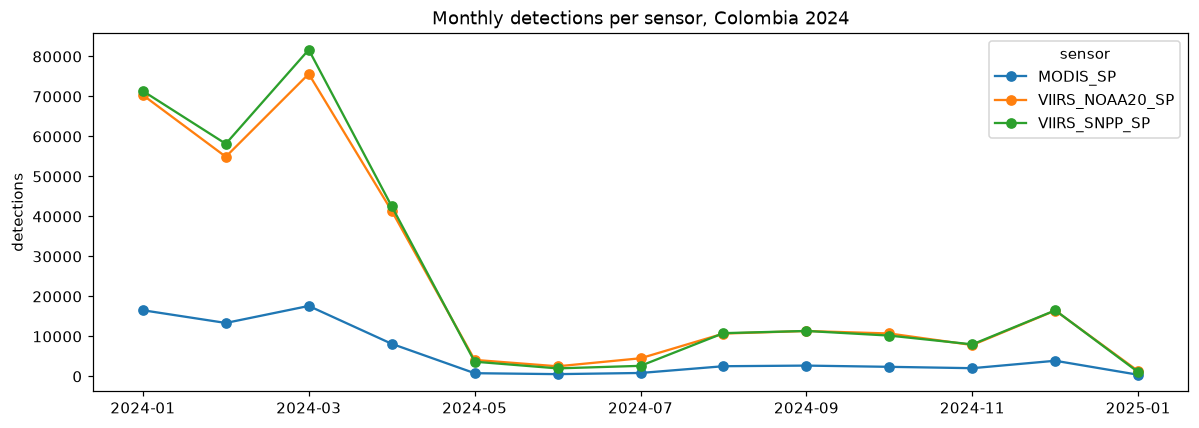

In [11]:
if not f1.empty:
    f1["acq_date"] = pd.to_datetime(f1.acq_date)
    comparison = (
        f1.groupby([f1.acq_date.dt.to_period("M"), "sensor"])
        .size()
        .unstack("sensor")
        .fillna(0)
        .astype(int)
    )
    comparison.index = comparison.index.astype(str)
    print("Detections per month and sensor (Colombia bbox):")
    print(comparison.to_string())
    print()
    print("Totals per sensor and the ratio between them:")
    totals = f1.groupby("sensor").size()
    print(totals.to_string())

    ax = comparison.plot(figsize=(11, 4), marker="o")
    ax.set_title("Monthly detections per sensor, Colombia 2024")
    ax.set_ylabel("detections")
    ax.set_xlabel("")
    plt.tight_layout()
    plt.savefig(FIGURES / "sensor_comparison_2024.png", dpi=140)
    plt.show()

## 3. F2: Open-Meteo historical (ERA5)

A daily panel built from hourly ERA5 values for the 33 region centroids, one
request per month with every coordinate in the same call, always with
`timezone=UTC`.

In [12]:
panel_path = RAW / "openmeteo" / "daily_panel.csv"
if panel_path.exists():
    weather = pd.read_csv(panel_path)
    profile_table(weather, "F2 Open-Meteo ERA5 daily panel")
    print()
    print("date range:", weather.date.min(), "->", weather.date.max())
    print("regions      :", weather.region_id.nunique())
else:
    weather = pd.DataFrame()
    print("No weather panel yet: run tools/pull_weather.py --mode historical")

=== F2 Open-Meteo ERA5 daily panel: 108,735 rows x 9 columns ===

date range: 2018-01-01 -> 2026-11-09
regions      : 33


In [13]:
if not weather.empty:
    summary = weather[["temp_max_c", "temp_min_c", "rh_min_pct", "precip_mm", "wind_max_kmh", "vpd_max_kpa"]].describe().T
    print(summary.round(2).to_string())
    print()
    print("nulls per variable:")
    print(weather[["temp_max_c", "rh_min_pct", "precip_mm", "vpd_max_kpa"]].isna().sum().to_string())

                 count   mean    std   min   25%    50%    75%     max
temp_max_c    108735.0  28.08   5.95  6.90  26.0  29.50  32.10   41.10
temp_min_c    108735.0  20.52   5.84 -1.00  18.6  22.50  24.30   29.60
rh_min_pct    108735.0  64.11  13.93  8.00  56.0  66.00  75.00   97.00
precip_mm     108735.0   8.88  12.94  0.00   0.6   4.50  12.20  254.50
wind_max_kmh  108735.0   9.64   5.61  2.00   6.3   8.10  10.70   87.60
vpd_max_kpa   108735.0   1.49   0.91  0.06   0.8   1.27   1.93    7.11

nulls per variable:
temp_max_c     0
rh_min_pct     0
precip_mm      0
vpd_max_kpa    0


## 4. Weather context: do dry days carry more detections?

A deliberately simple test of the assumption the indicator rests on. If dry days
with a high vapour pressure deficit do not carry more detections, the design is
wrong and it is better to find out now.

Correlation between detections and weather (national, 2024):
detections     1.000
precip_mm     -0.509
precip_7d     -0.597
vpd_max_kpa    0.784
temp_max_c     0.650


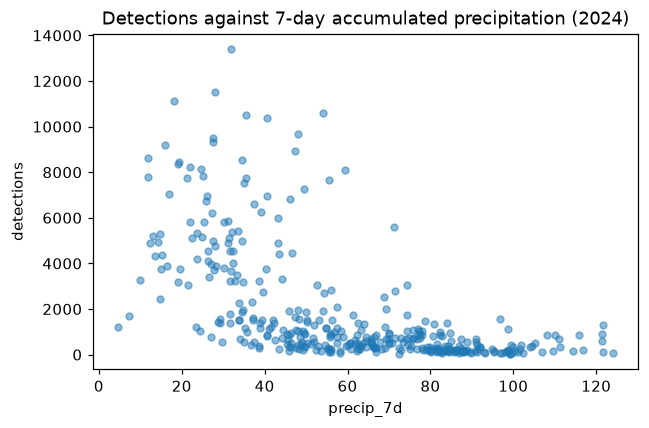

In [14]:
if not f1.empty and not weather.empty:
    fires_daily = f1.dropna(subset=["latitude", "longitude"]).copy()
    fires_daily["date"] = pd.to_datetime(fires_daily["acq_date"]).dt.normalize()
    daily = (
        fires_daily.groupby("date")
        .size()
        .rename("detections")
        .reset_index()
    )
    weather["date"] = pd.to_datetime(weather["date"])
    national = weather.groupby("date")[["precip_mm", "vpd_max_kpa", "temp_max_c"]].mean().reset_index()
    merged = daily.merge(national, on="date", how="inner")

    if len(merged) > 30:
        merged["precip_7d"] = merged.precip_mm.rolling(7, min_periods=1).sum()
        print("Correlation between detections and weather (national, 2024):")
        print(merged[["detections", "precip_mm", "precip_7d", "vpd_max_kpa", "temp_max_c"]].corr()["detections"].round(3).to_string())
        ax = merged.plot.scatter(x="precip_7d", y="detections", alpha=0.5, figsize=(6, 4))
        ax.set_title("Detections against 7-day accumulated precipitation (2024)")
        plt.tight_layout()
        plt.savefig(FIGURES / "detections_vs_precip.png", dpi=140)
        plt.show()

## 5. F4: Open-Meteo forecast, and the seam with F2

The forecast product and ERA5 do not come from the same model. Their overlap is
the only place where the two can be compared, and the size of the difference is
what the ingestion contract has to declare.

In [15]:
forecast_files = sorted((RAW / "openmeteo" / "forecast").glob("*.csv"))
if forecast_files:
    f4 = pd.read_csv(forecast_files[-1])
    profile_table(f4, "F4 Open-Meteo forecast")
    print()
    print("range:", f4.date.min(), "->", f4.date.max(), "| regions:", f4.region_id.nunique())
else:
    f4 = pd.DataFrame()
    print("No forecast data yet: run tools/pull_weather.py --mode forecast")

=== F4 Open-Meteo forecast: 462 rows x 9 columns ===

range: 2026-11-09 -> 2026-11-22 | regions: 33


In [16]:
if not f4.empty and not weather.empty:
    f4["date"] = pd.to_datetime(f4.date)
    weather["date"] = pd.to_datetime(weather["date"])
    overlap_dates = sorted(set(f4.date) & set(weather.date))
    if overlap_dates:
        a = f4[f4.date.isin(overlap_dates)].groupby("date").temp_max_c.mean()
        b = weather[weather.date.isin(overlap_dates)].groupby("date").temp_max_c.mean()
        diff = (a - b).round(2)
        print(f"overlapping days: {len(overlap_dates)}")
        print("temp_max difference (°C) between forecast and ERA5:")
        print(diff.to_string())
    else:
        print("No overlapping days between F4 and F2")

overlapping days: 1
temp_max difference (°C) between forecast and ERA5:
date
2026-11-09   -0.52


## 6. Overlap: the same fire seen twice

Candidate pairs are NOAA-20 and NOAA-21 detections on the same day, within about
2 km and 10 minutes of each other. One fire, two records.

In [17]:
def overlap_pairs(frame: pd.DataFrame, max_km: float = 2.0) -> pd.DataFrame:
    a = frame[frame.satellite == "N20"]
    b = frame[frame.satellite == "N21"]
    grid = {(round(r.latitude, 2), round(r.longitude, 2)): r
            for r in a.itertuples()}
    pairs = []
    for r in b.itertuples():
        key = (round(r.latitude, 2), round(r.longitude, 2))
        cand = grid.get(key)
        if cand is None:
            continue
        dy = (r.latitude - cand.latitude) * 111.0
        dx = (r.longitude - cand.longitude) * 111.0 * np.cos(np.radians(r.latitude))
        dist = float(np.hypot(dx, dy))
        if dist <= max_km:
            pairs.append({
                "date": r.acq_date,
                "n20_time": cand.acq_time, "n21_time": r.acq_time,
                "n20_frp": round(float(cand.frp), 2), "n21_frp": round(float(r.frp), 2),
                "dist_km": round(dist, 2),
                "n20_conf": cand.confidence, "n21_conf": r.confidence,
            })
        if len(pairs) >= 5:
            break
    return pd.DataFrame(pairs)


print("Candidate pairs, NOAA-20 and NOAA-21 (one fire, two records):")
print(overlap_pairs(f3).to_string(index=False))

Candidate pairs, NOAA-20 and NOAA-21 (one fire, two records):
      date  n20_time  n21_time  n20_frp  n21_frp  dist_km n20_conf n21_conf
2026-11-10       701       603     2.48     2.70     0.07        n        n
2026-11-10       644       603     3.76     2.46     0.16        n        n
2026-11-10       624       603     1.21     2.43     0.30        n        n
2026-11-10       605       603     1.97     1.92     0.26        n        n
2026-11-10       641       603     1.50     1.50     0.12        n        n


In every pair the timestamp differs because the overpass differs, the position
differs by up to about 2 km of geolocation spread, the FRP differs because the
pixel footprint differs, and the confidence code often changes too. None of the
sources provides an identifier, so the ingestion layer has to build one.

## 7. Summary export

One row per source, which is what the report cites.

In [18]:
summary = pd.DataFrame([
    {"source": "F1 firms_archive", "records_profiled": len(f1), "coverage": "2018-04 -> present",
     "format": "csv via API (SP)", "key_finding": "sensor change 2026 breaks naive baselines"},
    {"source": "F2 open_meteo_historical", "records_profiled": len(weather), "coverage": "2018 -> present",
     "format": "json (ERA5)", "key_finding": "local time unless timezone=UTC"},
    {"source": "F3 firms_nrt_viirs", "records_profiled": len(f3), "coverage": "last 5 days",
     "format": "csv (NRT)", "key_finding": "44.5% near-duplicates on a 1 km grid; 50% outside Colombia"},
    {"source": "F4 open_meteo_forecast", "records_profiled": len(f4), "coverage": "last 7 days + 7 ahead",
     "format": "json", "key_finding": "model seam with ERA5"},
])
summary.to_csv(ROOT / "workshop_1" / "profile_summary.csv", index=False)
print(summary.to_string(index=False))
print()
print("written:", ROOT / "workshop_1" / "profile_summary.csv")

                  source  records_profiled              coverage           format                                                key_finding
        F1 firms_archive            703633    2018-04 -> present csv via API (SP)                  sensor change 2026 breaks naive baselines
F2 open_meteo_historical            108735       2018 -> present      json (ERA5)                             local time unless timezone=UTC
      F3 firms_nrt_viirs              2220           last 5 days        csv (NRT) 44.5% near-duplicates on a 1 km grid; 50% outside Colombia
  F4 open_meteo_forecast               462 last 7 days + 7 ahead             json                                       model seam with ERA5

written: C:\Users\cesar\OneDrive\Documentos\2026-3\Data_Analysis_Programming\workshop_1\profile_summary.csv


## 8. What this forces in the design

Detection is not an event. With 44.5 % of rows sharing a ~1 km cell, the system
needs a `fire_event` table and a grouping rule before it aggregates anything.

Region assignment is not cosmetic either. Half the rows in the bounding box
belong to other countries.

The baseline has to be per sensor, because MODIS and the three VIIRS sensors
differ in footprint and in what they can detect.

Weather is stored as a series in `weather_observation`, never as an event, and
every request forces `timezone=UTC`.

Confidence gets normalised to one scale before any filter runs.

And the indicator has to condition on weather. A raw count compares a wet year
with a dry one and calls the difference an anomaly.